# SDS 336 Group Project: Exploratory Data Analysis
**Dataset:** Austin Police Department crime reports (`Crime_Reports_20261012.csv`, downloaded 2026-10-12)

What this notebook covers:
1. Loading the data and caching a cleaned copy
2. Data quality checks
3. Offense types
4. Trends over time and seasonality
5. Reporting delay
6. Geography and location type
7. Clearance (whether a case was solved)
8. Family violence
9. Takeaways and possible project questions

The first run reads the 530 MB CSV (about 30 seconds) and saves `data/processed/crime.parquet`. Later runs load the parquet file, which is much faster.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

# Works whether the notebook is run from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "Crime_Reports_20261012.csv"
CACHE = ROOT / "data" / "processed" / "crime.parquet"
FIG = ROOT / "figures"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Plot style: one accent blue, light grid, quiet axes
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})
SEQ = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
thousands = mtick.FuncFormatter(lambda x, _: f"{x/1000:,.4g}k" if x >= 1000 else f"{x:,.0f}")

def savefig(name):
    FIG.mkdir(exist_ok=True)
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Load and clean

In [2]:
CLEARANCE = {"C": "Cleared by arrest", "O": "Cleared by exception", "N": "Not cleared"}
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def load_raw(path):
    df = pd.read_csv(path, dtype=str)
    df.columns = (df.columns.str.strip().str.lower()
                    .str.replace(" ", "_", regex=False))
    fmt = "%m/%d/%Y %H:%M"
    for col in ["occurred_date_time", "report_date_time"]:
        # The raw file has two spaces between date and time
        df[col] = pd.to_datetime(df[col].str.split().str.join(" "), format=fmt, errors="coerce")
    df["clearance_date"] = pd.to_datetime(df["clearance_date"], format="%m/%d/%Y", errors="coerce")
    df = df.drop(columns=["occurred_date", "occurred_time", "report_date", "report_time"])

    df["family_violence"] = df["family_violence"].str.upper().eq("Y")
    df["clearance"] = df["clearance_status"].map(CLEARANCE)  # anything else -> NaN
    df["council_district"] = pd.to_numeric(df["council_district"], errors="coerce").astype("Int64")

    occ = df["occurred_date_time"]
    df["year"] = occ.dt.year.astype("Int64")
    df["month"] = occ.dt.month.astype("Int64")
    df["dow"] = occ.dt.dayofweek.astype("Int64")   # 0 = Monday
    df["hour"] = occ.dt.hour.astype("Int64")
    df["report_lag_days"] = (df["report_date_time"] - occ).dt.total_seconds() / 86400

    cat_cols = ["highest_offense_description", "location_type", "apd_sector", "apd_district",
                "clearance_status", "clearance", "ucr_category", "category_description"]
    for c in cat_cols:
        df[c] = df[c].astype("category")
    return df

if CACHE.exists():
    df = pd.read_parquet(CACHE)
    print("Loaded cached parquet")
else:
    df = load_raw(RAW)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(CACHE, index=False)
    print("Read raw CSV and wrote", CACHE.relative_to(ROOT))

print(f"{len(df):,} rows x {df.shape[1]} columns, "
      f"{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
df.head()

Loaded cached parquet
2,676,798 rows x 21 columns, 362 MB in memory


,incident_number,highest_offense_description,highest_offense_code,family_violence,occurred_date_time,report_date_time,location_type,council_district,apd_sector,apd_district,clearance_status,clearance_date,ucr_category,category_description,census_block_group,clearance,year,month,dow,hour,report_lag_days
0,2002923330284,FAMILY DISTURBANCE,3400,False,2003-01-29 05:30:00,2002-11-29 05:30:00,RESIDENCE / HOME,6,AD,3,N,NaT,NaN,NaN,4530341003,Not cleared,2003,1,2,5,-61.0
1,2003920010029,DEADLY CONDUCT,408,False,2003-01-01 00:01:00,2003-01-01 00:01:00,RESIDENCE / HOME,4,ID,4,N,NaT,13A,Aggravated Assault,4530021123,Not cleared,2003,1,2,0,0.0
2,2003920010046,BURGLARY NON RESIDENCE,502,False,2003-01-01 00:02:00,2003-01-01 00:02:00,COMMERCIAL / OFFICE BUILDING,2,DA,3,NaN,2003-10-18,220,Burglary,4530024101,NaN,2003,1,2,0,0.0
3,2003920010048,DEADLY CONDUCT,408,False,2003-01-01 00:03:00,2003-01-01 00:03:00,RESIDENCE / HOME,4,ID,2,C,2003-01-02,13A,Aggravated Assault,4530402001,Cleared by arrest,2003,1,2,0,0.0
4,2003920010079,RESISTING ARREST OR SEARCH,905,False,2003-01-01 00:06:00,2003-01-01 00:06:00,RESIDENCE / HOME,3,CH,2,C,2003-01-01,NaN,NaN,4530009021,Cleared by arrest,2003,1,2,0,0.0


In [3]:
df.dtypes

incident_number                           str
highest_offense_description          category
highest_offense_code                      str
family_violence                          bool
occurred_date_time             datetime64[us]
report_date_time               datetime64[us]
location_type                        category
council_district                        Int64
apd_sector                           category
apd_district                         category
clearance_status                     category
clearance_date                 datetime64[us]
ucr_category                         category
category_description                 category
census_block_group                        str
clearance                            category
year                                    Int64
month                                   Int64
dow                                     Int64
hour                                    Int64
report_lag_days                       float64
dtype: object

## 2. Data quality

In [4]:
missing = (df.isna().mean().mul(100).round(1)
             .rename("% missing").to_frame()
             .query("`% missing` > 0").sort_values("% missing", ascending=False))
missing

,% missing
ucr_category,63.0
category_description,63.0
clearance_status,23.8
clearance,23.8
clearance_date,13.7
census_block_group,2.3
council_district,1.6
location_type,0.6
apd_district,0.2
apd_sector,0.1


**Reading the missingness:**
- `ucr_category` / `category_description` are blank for about 63% of rows **on purpose**. They are filled in only for the serious "Part I" crimes (murder, rape, robbery, aggravated assault, burglary, theft, auto theft). Everything else, such as family disturbances, DWI or criminal mischief, has no UCR category.
- `clearance_status` is missing for about 24% of rows, and these rows are not random. Section 7 shows which offenses and years they come from.

In [5]:
occ, rep = df["occurred_date_time"], df["report_date_time"]
checks = {
    "duplicate incident numbers": df["incident_number"].duplicated().sum(),
    "unparseable occurred datetime": occ.isna().sum(),
    "reported BEFORE it occurred": (df["report_lag_days"] < 0).sum(),
    "reported > 1 year after occurring": (df["report_lag_days"] > 365).sum(),
    "occurred date after download date": (occ > "2026-10-12").sum(),
    "clearance date before occurrence": (df["clearance_date"] < occ.dt.normalize()).sum(),
    "odd clearance_status codes": df["clearance_status"].notna().sum() - df["clearance"].notna().sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
duplicate incident numbers,0
unparseable occurred datetime,60
reported BEFORE it occurred,186
reported > 1 year after occurring,14502
occurred date after download date,0
clearance date before occurrence,48
odd clearance_status codes,1


In [6]:
print("Occurred date range:", occ.min(), "to", occ.max())
print("Report date range:  ", rep.min(), "to", rep.max())

# APD sectors: the 9 main patrol sectors plus some rare codes
sector_counts = df["apd_sector"].value_counts()
print(f"\n{len(sector_counts[sector_counts > 0])} distinct APD sector codes; top 10 hold "
      f"{sector_counts.head(10).sum() / sector_counts.sum():.1%} of rows")
sector_counts.head(15)

Occurred date range: 2003-01-01 00:00:00 to 2026-10-03 23:58:00
Report date range:   2002-11-29 05:30:00 to 2026-10-04 05:12:00

64 distinct APD sector codes; top 10 hold 99.6% of rows


apd_sector
ED    363409
DA    340129
FR    330245
CH    309458
HE    295591
ID    287827
AD    264645
BA    250538
GE    205764
AP     14102
88      9536
UT      1430
AV       171
D         50
A          7
Name: count, dtype: int64

In [7]:
# Times that are exactly midnight or exactly on the hour are often placeholders for "unknown time"
minute = occ.dt.minute
print(f"Occurred at exactly 00:00: {(occ.dt.hour.eq(0) & minute.eq(0)).mean():.2%} of rows "
      f"(1/1440 = {1/1440:.2%} expected if times were uniform)")
print(f"Occurred on the hour (:00): {minute.eq(0).mean():.1%} (1/60 = {1/60:.1%} expected)")

Occurred at exactly 00:00: 2.24% of rows (1/1440 = 0.07% expected if times were uniform)
Occurred on the hour (:00): 25.7% (1/60 = 1.7% expected)


## 3. What gets reported

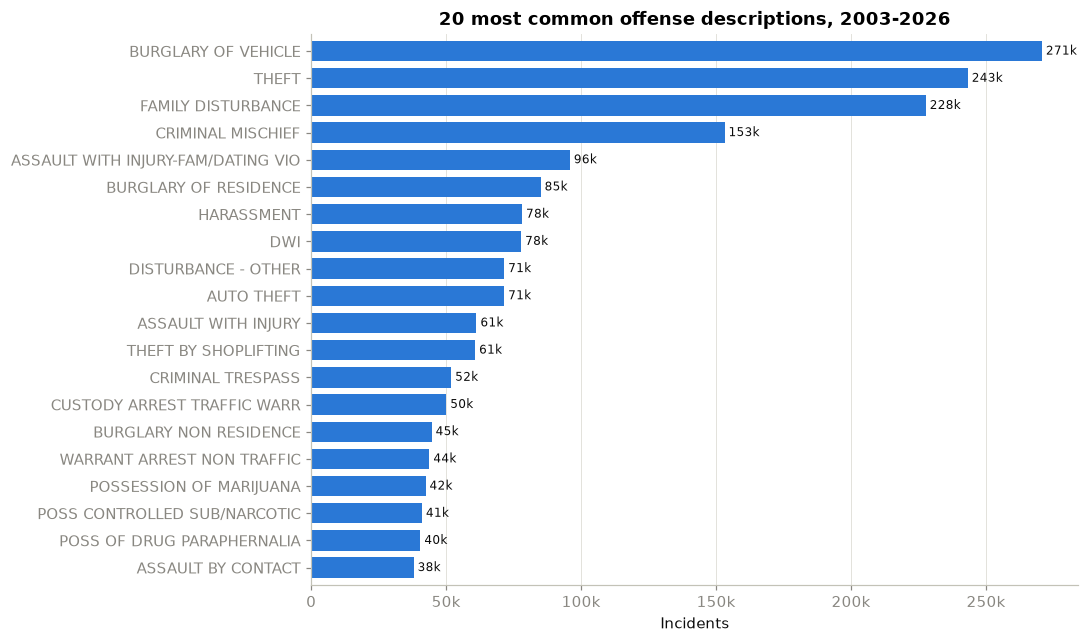

450 distinct offense descriptions; the top 20 are 69% of all incidents


In [8]:
top = df["highest_offense_description"].value_counts().head(20).sort_values()
ax = top.plot.barh(color=BLUE, width=0.75, figsize=(9, 6.5))
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
ax.set(title="20 most common offense descriptions, 2003-2026", xlabel="Incidents", ylabel="")
for y, v in enumerate(top):
    ax.text(v, y, f" {v/1000:,.0f}k", va="center", fontsize=8, color=INK)
savefig("top_offenses"); plt.show()

n_offense = df["highest_offense_description"].nunique()
print(f"{n_offense} distinct offense descriptions; the top 20 are "
      f"{top.sum() / len(df):.0%} of all incidents")

In [9]:
part1 = df["category_description"].value_counts().rename("incidents").to_frame()
part1["% of Part I"] = (part1["incidents"] / part1["incidents"].sum() * 100).round(1)
part1

,incidents,% of Part I
category_description,,
Theft,686648,69.4
Burglary,139672,14.1
Auto Theft,71496,7.2
Aggravated Assault,48835,4.9
Robbery,24914,2.5
Rape,17399,1.8
Murder,837,0.1


## 4. Trends over time

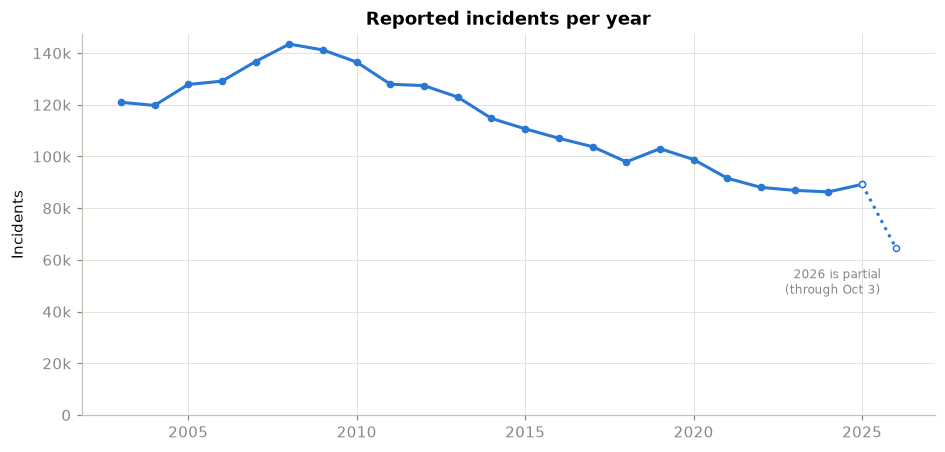

Peak: 2008 (143,485).  2025: 89,215 (-38% vs peak)


In [10]:
yearly = df.groupby("year").size()
full = yearly.loc[:2025]
ax = full.plot(color=BLUE, lw=2, marker="o", ms=4)
ax.plot([2025, 2026], [yearly[2025], yearly[2026]], color=BLUE, lw=2, ls=":", marker="o", ms=4, mfc="white")
ax.annotate("2026 is partial\n(through Oct 3)", (2026, yearly[2026]), xytext=(-10, -30),
            textcoords="offset points", ha="right", fontsize=8, color=MUTED)
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0)
ax.set(title="Reported incidents per year", xlabel="", ylabel="Incidents")
savefig("yearly_total"); plt.show()

peak = full.idxmax()
print(f"Peak: {peak} ({full[peak]:,}).  2025: {full[2025]:,} ({full[2025]/full[peak]-1:+.0%} vs peak)")

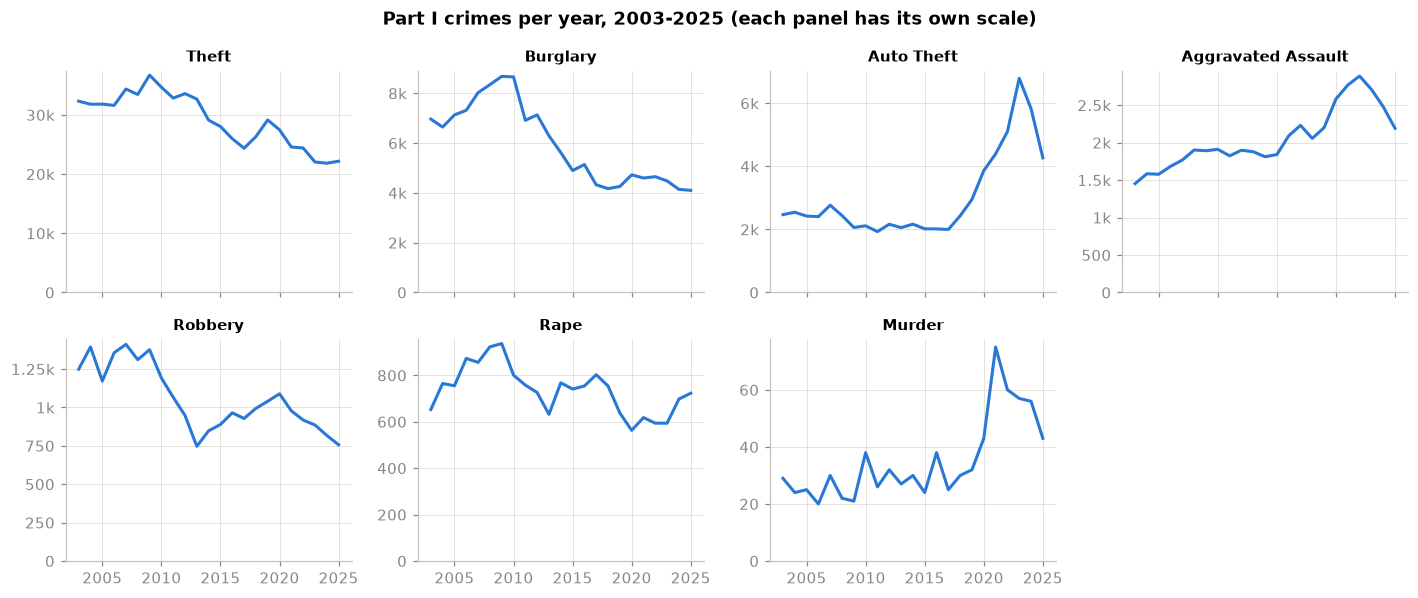

In [11]:
# Part I categories, one panel each (independent y-axes, so compare shapes, not heights)
cats = df["category_description"].value_counts().index.tolist()
by_cat = (df.dropna(subset=["category_description"])
            .groupby(["year", "category_description"], observed=True).size()
            .unstack().loc[:2025, cats])
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for ax, c in zip(axes.flat, cats):
    ax.plot(by_cat.index, by_cat[c], color=BLUE, lw=2)
    ax.set_title(c, fontsize=10); ax.set_ylim(0)
    ax.yaxis.set_major_formatter(thousands)
axes.flat[-1].set_visible(False)
fig.suptitle("Part I crimes per year, 2003-2025 (each panel has its own scale)", fontweight="bold")
fig.tight_layout(); savefig("yearly_by_category"); plt.show()

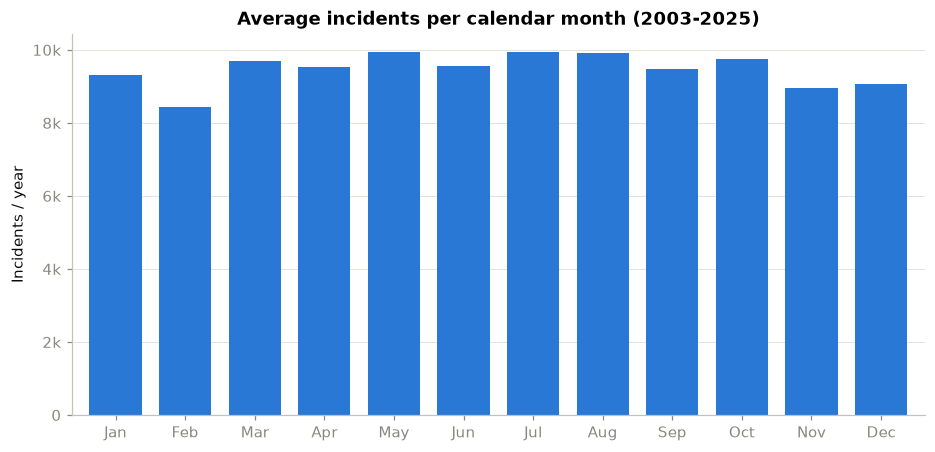

In [12]:
# Seasonality: average incidents per month across complete years
complete = df[df["year"].between(2003, 2025)]
monthly = complete.groupby("month").size() / complete["year"].nunique()
ax = monthly.plot.bar(color=BLUE, width=0.75, rot=0)
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.grid(axis="x", visible=False); ax.yaxis.set_major_formatter(thousands)
ax.set(title="Average incidents per calendar month (2003-2025)", xlabel="", ylabel="Incidents / year")
savefig("monthly"); plt.show()

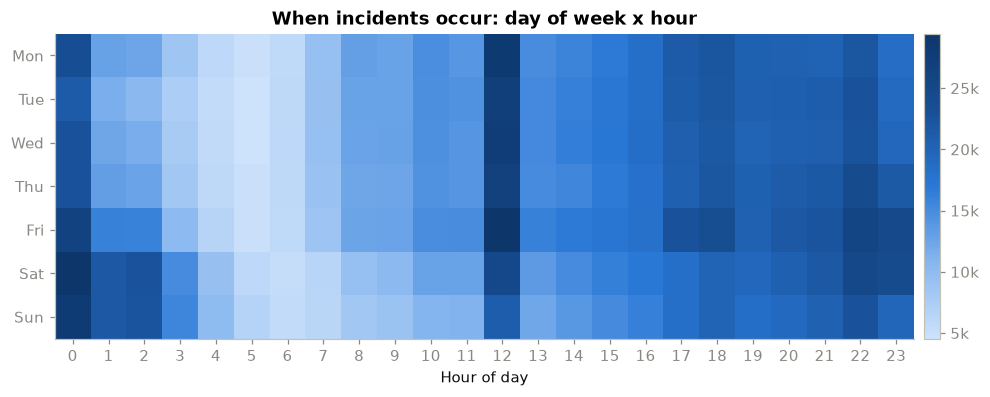

In [13]:
# Day of week x hour of day
heat = df.groupby(["dow", "hour"]).size().unstack()
heat.index = DOW
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(heat, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24)); ax.set_yticks(range(7)); ax.set_yticklabels(DOW)
ax.grid(False)
ax.set(title="When incidents occur: day of week x hour", xlabel="Hour of day")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.ax.yaxis.set_major_formatter(thousands)
savefig("dow_hour_heatmap"); plt.show()

Spikes at hour 0 and hour 12 probably come partly from placeholder times (see Section 2), not from real crime peaks.

## 5. Reporting delay

In [14]:
lag = df.loc[df["report_lag_days"] >= 0, ["report_lag_days", "category_description"]]
q = lag["report_lag_days"].quantile([0.25, 0.5, 0.75, 0.9, 0.99])
print("Report lag (days) quantiles:"); print(q.round(2).to_string())

lag_by_cat = (lag.dropna().groupby("category_description", observed=True)["report_lag_days"]
                 .agg(median="median", p90=lambda s: s.quantile(0.9), n="size")
                 .sort_values("median"))
lag_by_cat.round(2)

Report lag (days) quantiles:
0.25      0.00
0.50      0.01
0.75      0.53
0.90      4.37
0.99    164.18


,median,p90,n
category_description,,,
Aggravated Assault,0.00,0.28,48829
Murder,0.00,0.18,837
Robbery,0.00,0.18,24913
Rape,0.16,128.00,17398
Auto Theft,0.20,2.72,71488
Burglary,0.31,6.14,139661
Theft,0.45,9.06,686578


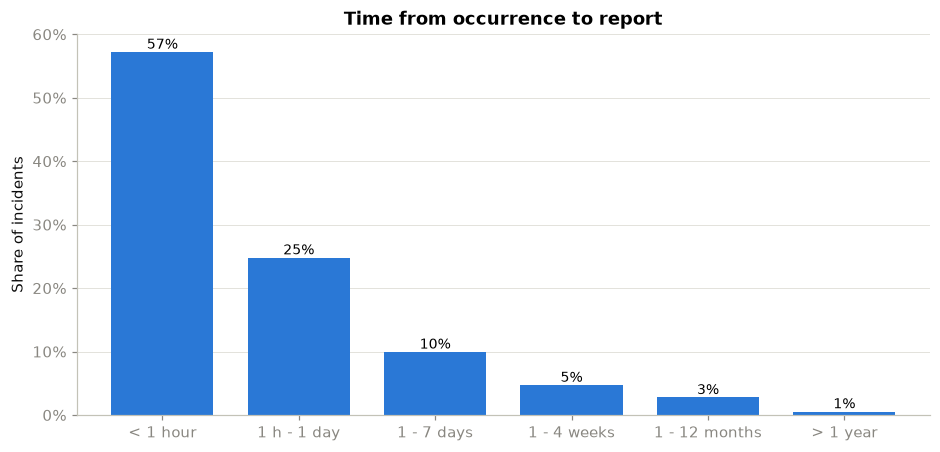

In [15]:
bins = [0, 1/24, 1, 7, 30, 365, np.inf]
labels = ["< 1 hour", "1 h - 1 day", "1 - 7 days", "1 - 4 weeks", "1 - 12 months", "> 1 year"]
lag_bucket = pd.cut(lag["report_lag_days"], bins=bins, labels=labels, right=False)
share = lag_bucket.value_counts(normalize=True).reindex(labels)
ax = share.plot.bar(color=BLUE, width=0.75, rot=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.grid(axis="x", visible=False)
ax.set(title="Time from occurrence to report", xlabel="", ylabel="Share of incidents")
for x, v in enumerate(share):
    ax.text(x, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
savefig("report_lag"); plt.show()

## 6. Where

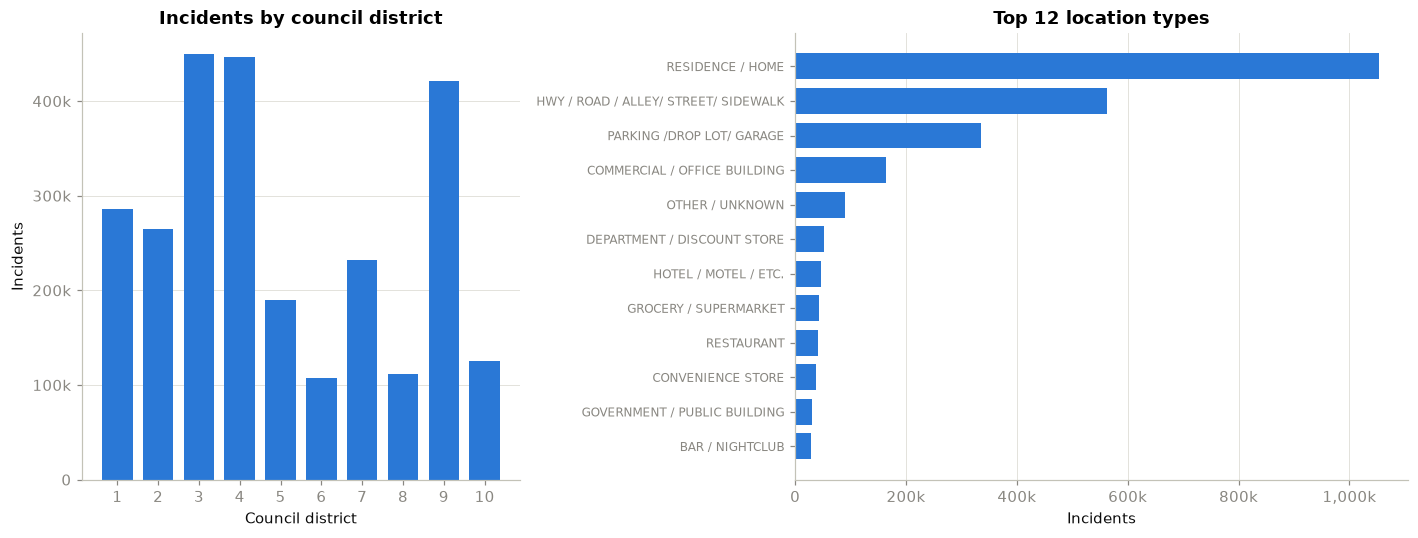

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})

cd = df["council_district"].value_counts().sort_index()
a1.bar(cd.index.astype(str), cd.values, color=BLUE, width=0.75)
a1.yaxis.set_major_formatter(thousands); a1.grid(axis="x", visible=False)
a1.set(title="Incidents by council district", xlabel="Council district", ylabel="Incidents")

loc = df["location_type"].value_counts().head(12).sort_values()
a2.barh(loc.index, loc.values, color=BLUE, height=0.75)
a2.xaxis.set_major_formatter(thousands); a2.grid(axis="y", visible=False)
a2.set(title="Top 12 location types", xlabel="Incidents")
a2.tick_params(axis="y", labelsize=8)
fig.tight_layout(); savefig("geography"); plt.show()

Austin's council districts started in 2015. For earlier incidents, the district was probably assigned afterwards from the location. Districts also differ in population, so these are raw counts, **not rates**.

## 7. Clearance (was the case solved?)

`clearance_status`: **C** = cleared by arrest, **O** = cleared by exception (for example, the suspect died or the victim declined to prosecute), **N** = not cleared.

clearance
Not cleared             50.5
NaN                     23.8
Cleared by arrest       22.6
Cleared by exception     3.1
Rows with no status but a clearance date: 11.1%


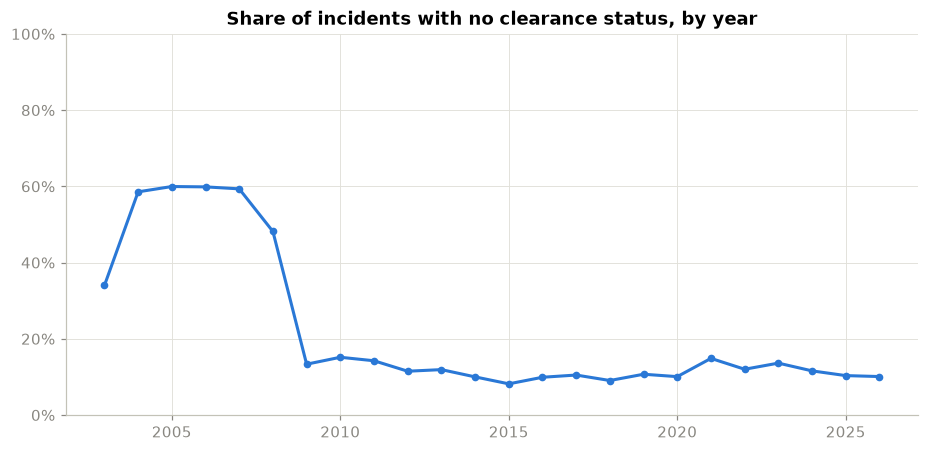

In [17]:
print(df["clearance"].value_counts(dropna=False, normalize=True).mul(100).round(1).to_string())

# Missing clearance status by year: is it a reporting-era artifact?
miss_by_year = df.groupby("year")["clearance_status"].apply(lambda s: s.isna().mean())
print(f"Rows with no status but a clearance date: "
      f"{(df['clearance_status'].isna() & df['clearance_date'].notna()).mean():.1%}")
ax = miss_by_year.plot(color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, 1)
ax.set(title="Share of incidents with no clearance status, by year", xlabel="", ylabel="")
savefig("clearance_missing_by_year"); plt.show()

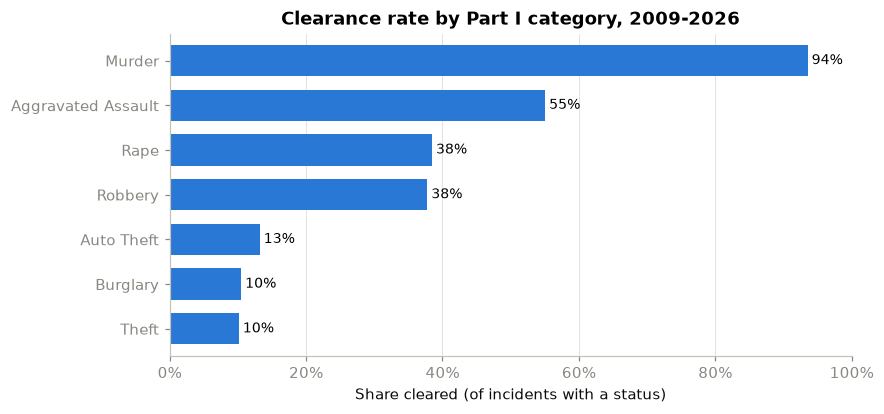

In [18]:
# Clearance rate among incidents that HAVE a status (C or O counts as cleared)
# Restricted to 2009+: before then, coding was inconsistent (see the missing-status chart above)
known = df[df["year"] >= 2009].dropna(subset=["clearance"]).copy()
known["cleared"] = known["clearance"].ne("Not cleared")

rate = (known.dropna(subset=["category_description"])
             .groupby("category_description", observed=True)["cleared"].mean().sort_values())
ax = rate.plot.barh(color=BLUE, width=0.7, figsize=(8, 3.8))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set(title="Clearance rate by Part I category, 2009-2026", xlabel="Share cleared (of incidents with a status)", ylabel="")
for y, v in enumerate(rate):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9)
savefig("clearance_by_category"); plt.show()

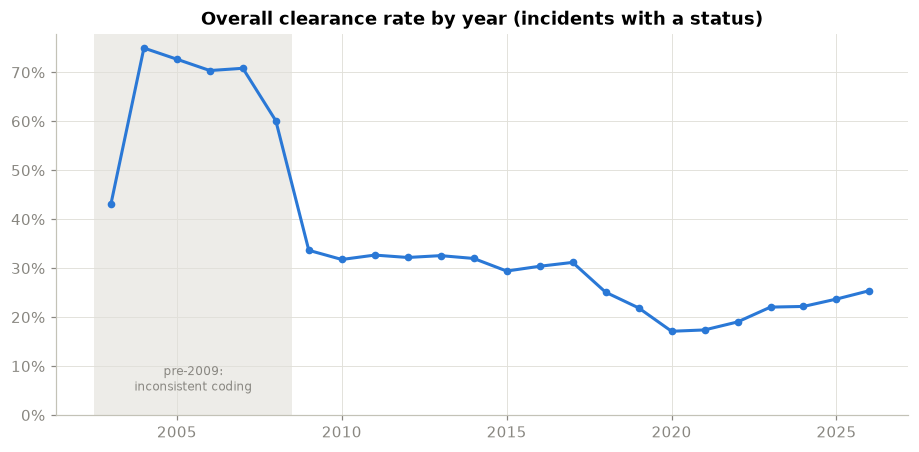

year
2009    0.336
2010    0.318
2011    0.327
2012    0.322
2013    0.326
2014    0.320
2015    0.294
2016    0.304
2017    0.312
2018    0.251
2019    0.219
2020    0.171
2021    0.174
2022    0.190
2023    0.220
2024    0.222
2025    0.237
2026    0.254


In [19]:
all_known = df.dropna(subset=["clearance"])
rate_year = all_known["clearance"].ne("Not cleared").groupby(all_known["year"]).mean()
ax = rate_year.plot(color=BLUE, lw=2, marker="o", ms=4)
ax.axvspan(2002.5, 2008.5, color=GRID, alpha=0.6, lw=0)
ax.text(2005.5, 0.05, "pre-2009:\ninconsistent coding", ha="center", fontsize=8, color=MUTED)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0)
ax.set(title="Overall clearance rate by year (incidents with a status)", xlabel="", ylabel="")
savefig("clearance_by_year"); plt.show()
print(rate_year.loc[2009:].round(3).to_string())

## 8. Family violence

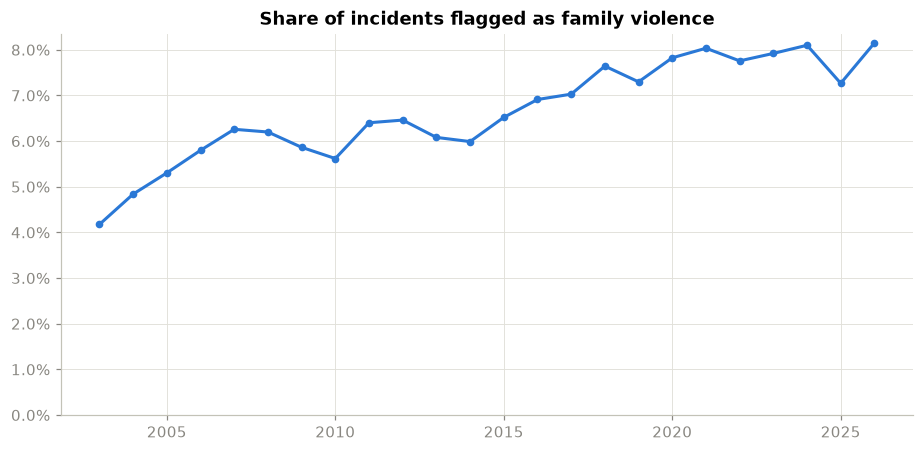

,FV incidents
highest_offense_description,
ASSAULT WITH INJURY-FAM/DATING VIO,89150
ASSAULT BY CONTACT-FAM/DATING VIO,14214
AGGRAVATED ASSAULT-FAM/DATING VIO,9930
AGG ASLT STRANGLE/SUFFOCATE,9081
FELONY ENHANCEMENT/ASSLT W/INJ,6595
HARASSMENT,5866
ASSAULT BY THREAT-FAM/DATING VIO,4112
TERRORISTIC THREAT-FAM/DATING VIO,3903
FAMILY DISTURBANCE,2099


In [20]:
fv_year = df.groupby("year")["family_violence"].mean()
ax = fv_year.plot(color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0)
ax.set(title="Share of incidents flagged as family violence", xlabel="", ylabel="")
savefig("family_violence_share"); plt.show()

fv_top = (df.loc[df["family_violence"], "highest_offense_description"]
            .value_counts().head(10).rename("FV incidents").to_frame())
fv_top

## 9. Takeaways and possible project questions

### What the data looks like
- **2.68M incidents, 2003 to Oct 3, 2026**, with one row per incident and no duplicate incident numbers. 2026 is a partial year, so leave it out of year-over-year comparisons.
- **450 offense descriptions**, but the top 20 cover 69% of incidents. The most common are burglary of vehicle, theft, family disturbance and criminal mischief.
- **UCR category is filled in only for Part I crimes (37% of rows).** Theft makes up 69% of Part I crimes and murder 0.1%, so any model that predicts category is very imbalanced.

### Data quality issues to handle
- **Occurrence times are unreliable.** 25.7% of incidents are recorded exactly on the hour (1.7% would be expected) and 2.2% at exactly midnight. The spikes at hours 0 and 12 in the heatmap are mostly these placeholder times. Use hour-of-day features carefully, or round them.
- **Clearance coding changed around 2009.** In 2004-2008, about 60% of statuses are missing and the clearance rate is 60-75%. From 2009 on, about 10-15% are missing and the rate is 17-34%. **Use 2009 and later for anything involving clearance.**
- Small issues: 60 rows have unparseable dates, 186 were reported before they occurred, and 54 sector codes cover only 0.4% of rows. These are safe to drop.

### Patterns
- **Total reported incidents fell 38%**, from 143k at the 2008 peak to 89k in 2025. The categories moved differently: **auto theft roughly tripled from 2019 to 2023** before falling, **murder jumped in 2021** (to about 75) and has come down since, and **aggravated assault rose through about 2023**.
- **Seasonality is weak.** Monthly volume stays within about ±5% of average, with February lowest.
- **Weekly and daily rhythm:** incidents are fewest around 5-6 am. Friday and Saturday nights are the busiest, and Saturday and Sunday from midnight to 2 am stand out.
- **Reporting delay:** the median is about 15 minutes, but 10% of incidents are reported 4 or more days later. **Rape has a 90th-percentile delay of 128 days**, compared with hours for robbery and assault.
- **Clearance (2009 and later) depends heavily on crime type:** murder 94%, aggravated assault 55%, rape and robbery 38% each, and only 10-13% for theft, burglary and auto theft. The overall rate fell to 17% in 2020-21 and has been rising since.
- **Family violence** went from 4% of incidents in 2003 to about 8% now. It is mostly assault with injury.
- Council districts 3, 4 and 9 have the most incidents, but these are raw counts. Use per-capita rates (census population by block group) before comparing districts.

### Possible project questions (SDS 336 methods)
1. **Will a case be cleared?** Classification (logistic regression, trees, ensembles) using offense, location type, sector, time, report delay and family-violence flag, on 2009+ data. Watch for class imbalance and for leakage from `clearance_date`.
2. **Predict the Part I category** from where, when and how quickly an incident was reported. This is a multiclass problem with heavy imbalance.
3. **Forecast incident counts** by sector and week, or compare 2020-2023 against the pre-COVID trend.
4. **Cluster census block groups** by their crime mix (k-means or hierarchical) and map the clusters.
5. **Does reporting delay predict clearance?** Use local or linear regression and control for offense type.